# Finding Similar arXiv Abstracts

The aim is to find papers with similar abstract wording. Each abstract becomes a set of word shingles. MinHash and LSH reduce the number of pairs to compare, and exact Jaccard similarity decides which pairs to keep.


## 1. Setup
Install the packages, import the libraries, and choose the main settings. firstly,I use only a small part of the dataset by default.


In [ ]:
%pip install -q "kaggle==2.2.5" "six>=1.16,<2" "pandas>=2,<3" "matplotlib>=3.9,<4"


In [ ]:
import hashlib
import json
import random
import re
import tempfile
from itertools import combinations
from pathlib import Path
from time import perf_counter

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


In [ ]:
USE_SAMPLE = True
SAMPLE_SIZE = 5000
CATEGORY = "cs.IR"
SHINGLE_SIZE = 3
NUM_HASHES = 120
NUM_BANDS = 40
THRESHOLD = 0.5
SEED = 42
EVALUATION_SIZE = 5000
RUN_EXPERIMENTS = True

DATA_DIR = Path("data")
OUTPUT_DIR = Path("results/simple")
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_FILE = DATA_DIR / "arxiv-metadata-oai-snapshot.json"

assert SAMPLE_SIZE >= 2 and SHINGLE_SIZE >= 1
assert NUM_HASHES > 0 and NUM_BANDS > 0 and NUM_HASHES % NUM_BANDS == 0
assert 0 < THRESHOLD <= 1 and EVALUATION_SIZE >= 2


## 2. Load Dataset
Upload `kaggle.json` or `kaggle (2).json` when prompted. The key stays outside the notebook and is not printed. For local Jupyter use, put the file at `~/.kaggle/kaggle.json` first.


In [ ]:
credential_file = Path.home() / ".kaggle/kaggle.json"
if not credential_file.exists():
    from google.colab import files
    with tempfile.TemporaryDirectory() as folder:
        uploaded = files.upload(target_dir=folder)
        assert len(uploaded) == 1, "Upload one Kaggle JSON file."
        credentials = json.loads(next(iter(uploaded.values())))
        assert credentials.get("username") and credentials.get("key")
        credential_file.parent.mkdir(exist_ok=True)
        credential_file.write_text(json.dumps(credentials))
        credential_file.chmod(0o600)
    del uploaded, credentials
print("Kaggle credentials are ready.")


Saving kaggle (2).json to /tmp/tmpng48994z/kaggle (2).json
Kaggle credentials are ready.


In [ ]:
if not DATA_FILE.exists():
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi()
    api.authenticate()
    # Move the file into place only after the download finishes.
    with tempfile.TemporaryDirectory(dir=DATA_DIR) as folder:
        api.dataset_download_files("Cornell-University/arxiv", path=folder, unzip=True)
        (Path(folder) / DATA_FILE.name).replace(DATA_FILE)
print("Dataset ready:", DATA_FILE)


Dataset URL: https://www.kaggle.com/datasets/Cornell-University/arxiv
Dataset ready: data/arxiv-metadata-oai-snapshot.json


We read one JSON record at a time. Reservoir sampling keeps a fixed number of papers while giving every eligible paper the same chance of selection. Setting `USE_SAMPLE=False` keeps all eligible records, so memory use will grow.


In [ ]:
def load_papers(limit):
    rng = random.Random(SEED)
    papers = []
    eligible = 0
    with DATA_FILE.open(encoding="utf-8") as source:
        for count, line in enumerate(source, 1):
            record = json.loads(line)
            categories = record.get("categories", "").split()
            abstract = record.get("abstract", "")
            if CATEGORY and not any(c.startswith(CATEGORY) for c in categories):
                continue
            if len(re.findall(r"[a-z0-9]+", abstract.lower())) < SHINGLE_SIZE:
                continue
            paper = {key: record[key] for key in ("id", "title", "abstract")}
            eligible += 1
            if limit is None or len(papers) < limit:
                papers.append(paper)
            else:
                position = rng.randrange(eligible)
                if position < limit:
                    papers[position] = paper
    print(f"Read {count:,} records; eligible: {eligible:,}; selected: {len(papers):,}.")
    return sorted(papers, key=lambda paper: paper["id"])

papers = load_papers(SAMPLE_SIZE if USE_SAMPLE else None)
assert len(papers) >= 2, "The selected data must contain at least two abstracts."


Read 3,252,452 records; eligible: 28,166; selected: 5,000.


## 3. Preprocessing
We lowercase the abstracts and keep words and numbers. A 3-word shingle is a group of three consecutive tokens. Repeated shingles occur only once in the set.


In [ ]:
def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())

print(tokenize("A Simple Example: text similarity!"))


['a', 'simple', 'example', 'text', 'similarity']


In [ ]:
def make_shingles(text, k=SHINGLE_SIZE):
    words = tokenize(text)
    return {" ".join(words[i:i + k]) for i in range(len(words) - k + 1)}

started = perf_counter()
shingle_sets = [make_shingles(paper["abstract"]) for paper in papers]
shingling_seconds = perf_counter() - started
print("Example shingles:", sorted(make_shingles("we compare short scientific abstracts", 3)))


Example shingles: ['compare short scientific', 'short scientific abstracts', 'we compare short']


## 4. Jaccard Similarity
Jaccard similarity is the number of shared shingles divided by the number of distinct shingles in either abstract: $J(A,B)=|A\cap B|/|A\cup B|$.


In [ ]:
def jaccard(left, right):
    intersection = len(left & right)
    union = len(left) + len(right) - intersection
    return intersection / union if union else 0.0


In [ ]:
example_a = {"a", "b", "c"}
example_b = {"b", "c", "d"}
assert jaccard(example_a, example_b) == 0.5
print("Example Jaccard:", jaccard(example_a, example_b))


Example Jaccard: 0.5


## 5. MinHash
Each hash function gives the shingles a different order. We keep its smallest hash value. The fraction of matching entries in two signatures estimates their Jaccard similarity.

We use $h(x)=(ax+b)\bmod p$ with shared random parameters. A stable hash first converts each shingle to an integer. This avoids Python's built-in hash changing between runs. These hash functions approximate random permutations.


In [ ]:
PRIME = 2**61 - 1

def create_hash_functions(length):
    rng = random.Random(SEED)
    return [(rng.randrange(1, PRIME), rng.randrange(PRIME)) for _ in range(length)]


In [ ]:
def minhash_signature(shingles, hash_functions):
    values = []
    for shingle in shingles:
        digest = hashlib.blake2b(shingle.encode(), digest_size=8).digest()
        values.append(int.from_bytes(digest, "big") % PRIME)
    return tuple(min((a * value + b) % PRIME for value in values)
                 for a, b in hash_functions)

def build_signatures(sets, length):
    hash_functions = create_hash_functions(length)
    return [minhash_signature(s, hash_functions) for s in sets]

started = perf_counter()
signatures = build_signatures(shingle_sets, NUM_HASHES)
minhash_seconds = perf_counter() - started
print(f"Built {len(signatures):,} signatures with {NUM_HASHES} entries each.")


Built 5,000 signatures with 120 entries each.


In [ ]:
def minhash_similarity(left, right):
    return sum(a == b for a, b in zip(left, right)) / len(left)

example_hashes = create_hash_functions(NUM_HASHES)
example_sig = minhash_signature(example_a, example_hashes)
assert minhash_similarity(example_sig, example_sig) == 1.0
print("Example MinHash estimate:", minhash_similarity(
    example_sig, minhash_signature(example_b, example_hashes)))


Example MinHash estimate: 0.5416666666666666


## 6. LSH
Split each signature into bands. Two papers become a candidate pair if one corresponding band matches completely. Including the band number in the bucket key prevents matches between different band positions.

With $b$ bands and $r$ rows per band, the approximate candidate probability is $1-(1-s^r)^b$ for Jaccard similarity $s$. More bands usually produce more candidates and fewer missed matches.


In [ ]:
def lsh_candidates(signatures, bands):
    assert bands > 0 and len(signatures[0]) % bands == 0
    rows = len(signatures[0]) // bands
    buckets = {}
    for j, signature in enumerate(signatures):
        candidates = set()
        for band in range(bands):
            start = band * rows
            key = (band, signature[start:start + rows])
            if key not in buckets:
                buckets[key] = []
            candidates.update(buckets[key])
            buckets[key].append(j)
        # A pair may share several bands, but it is yielded only once.
        for i in sorted(candidates):
            yield i, j


In [ ]:
small_signatures = [(1, 2, 3, 4), (1, 2, 8, 9), (8, 9, 1, 2)]
assert list(lsh_candidates(small_signatures, 2)) == [(0, 1)]
print("Example candidate pairs:", list(lsh_candidates(small_signatures, 2)))


Example candidate pairs: [(0, 1)]


## 7. Find Similar Papers
Only candidate pairs receive an exact Jaccard comparison. The same threshold is used here and in the evaluation. The table shows the best matches first and is also saved as a CSV.


In [ ]:
def find_similar_pairs(sets, signatures, bands):
    matches = {}
    candidate_count = 0
    for i, j in lsh_candidates(signatures, bands):
        candidate_count += 1
        score = jaccard(sets[i], sets[j])
        if score >= THRESHOLD:
            matches[i, j] = score
    return matches, candidate_count


In [ ]:
started = perf_counter()
matches, candidate_count = find_similar_pairs(shingle_sets, signatures, NUM_BANDS)
search_seconds = perf_counter() - started
all_pairs = len(papers) * (len(papers) - 1) // 2
print(f"All possible pairs: {all_pairs:,}; candidates: {candidate_count:,}; matches: {len(matches)}")
print(f"Detection time: {shingling_seconds + minhash_seconds + search_seconds:.2f} seconds")

match_rows = []
for (i, j), score in sorted(matches.items(), key=lambda item: item[1], reverse=True):
    match_rows.append([papers[i]["id"], papers[j]["id"], score,
                       " ".join(papers[i]["title"].split()), " ".join(papers[j]["title"].split())])
match_table = pd.DataFrame(match_rows, columns=["paper_1", "paper_2", "jaccard", "title_1", "title_2"])
display(match_table.head(10))
match_table.to_csv(OUTPUT_DIR / "similar_pairs.csv", index=False)


All possible pairs: 12,497,500; candidates: 16; matches: 5
Detection time: 58.82 seconds


,paper_1,paper_2,jaccard,title_1,title_2
0,2311.04091,2411.15741,0.866667,Proceedings of the 5th International Workshop ...,Proceedings of the 6th International Workshop ...
1,2301.10062,2311.04091,0.861314,Proceedings of the 1st International Workshop ...,Proceedings of the 5th International Workshop ...
2,2301.10062,2411.15741,0.860294,Proceedings of the 1st International Workshop ...,Proceedings of the 6th International Workshop ...
3,1910.05755,2008.09273,0.619266,The Impact of Popularity Bias on Fairness and ...,"The Connection Between Popularity Bias, Calibr..."
4,1908.08478,2001.09006,0.559259,Two Decades of Network Science as seen through...,Twenty Years of Network Science: A Bibliograph...


## 8. Evaluation
We independently check every pair in a sample of at most 5,000 papers. A pair can be skipped safely when the smaller shingle set divided by the larger set is below the threshold: its intersection cannot be larger than the smaller set.

Recall is the fraction of exact matches found by LSH. If there are no exact matches, recall is undefined. This evaluates matching text, not semantic similarity. The exact check takes quadratic time, so we keep its size bounded.


In [ ]:
def exact_matches(sets):
    positives = {}
    sizes = [len(s) for s in sets]
    for i, j in combinations(range(len(sets)), 2):
        if min(sizes[i], sizes[j]) / max(sizes[i], sizes[j]) < THRESHOLD:
            continue
        score = jaccard(sets[i], sets[j])
        if score >= THRESHOLD:
            positives[i, j] = score
    return positives


In [ ]:
rng = random.Random(SEED)
eval_indices = sorted(rng.sample(range(len(papers)), min(EVALUATION_SIZE, len(papers))))
eval_sets = [shingle_sets[i] for i in eval_indices]
eval_signatures = [signatures[i] for i in eval_indices]
print(f"Checking all pairs among {len(eval_sets):,} evaluation papers...")
started = perf_counter()
truth = exact_matches(eval_sets)
audit_seconds = perf_counter() - started
eval_matches, _ = find_similar_pairs(eval_sets, eval_signatures, NUM_BANDS)
missed = set(truth) - set(eval_matches)
recall = len(eval_matches) / len(truth) if truth else None
print(f"Exact matches: {len(truth)}; missed: {len(missed)}; recall: {recall}")
print(f"Exact evaluation time: {audit_seconds:.2f} seconds")
for i, j in sorted(missed)[:10]:
    print("Missed:", papers[eval_indices[i]]["id"], papers[eval_indices[j]]["id"])


Checking all pairs among 5,000 evaluation papers...
Exact matches: 5; missed: 0; recall: 1.0
Exact evaluation time: 94.64 seconds


## 9. Experiments
Each experiment changes one aspect of the method. Timings are single runs on the current machine, so small differences should not be overinterpreted. Set `RUN_EXPERIMENTS=False` to skip this section and the three plots.

### 9.1 Scalability
Compare 1,000, 2,000, 5,000, and 10,000 abstracts from a fixed shuffled sample. Smaller inputs are prefixes of the larger input. Time includes shingling, MinHash, LSH, and exact candidate checks. Downloading, loading, and the separate all-pairs evaluation are excluded.


In [ ]:
if RUN_EXPERIMENTS:
    scale_papers = load_papers(10000)
    assert len(scale_papers) == 10000, "Choose a category with at least 10,000 eligible abstracts."
    random.Random(SEED).shuffle(scale_papers)


Read 3,252,452 records; eligible: 28,166; selected: 10,000.


In [ ]:
if RUN_EXPERIMENTS:
    scale_rows = []
    for size in [1000, 2000, 5000, 10000]:
        started = perf_counter()
        sets = [make_shingles(p["abstract"]) for p in scale_papers[:size]]
        sigs = build_signatures(sets, NUM_HASHES)
        found, candidates = find_similar_pairs(sets, sigs, NUM_BANDS)
        seconds = perf_counter() - started
        scale_rows.append([size, seconds, candidates, len(found)])
        print(f"Scalability: {size:,} papers, {seconds:.2f} seconds")
    scale_table = pd.DataFrame(scale_rows, columns=["papers", "seconds", "candidates", "matches"])


Scalability: 1,000 papers, 8.06 seconds
Scalability: 2,000 papers, 24.25 seconds
Scalability: 5,000 papers, 62.02 seconds
Scalability: 10,000 papers, 102.82 seconds


### 9.2 MinHash signature length
Use the same evaluation papers for lengths 50, 100, and 150. Compare signature-building time and mean absolute error (MAE) against exact Jaccard. The same random pairs are used for all lengths. We also measure error on all exact-positive pairs, since random pairs are mostly dissimilar.


In [ ]:
if RUN_EXPERIMENTS:
    rng = random.Random(SEED)
    error_pairs = set()
    pair_limit = min(10000, len(eval_sets) * (len(eval_sets) - 1) // 2)
    while len(error_pairs) < pair_limit:
        i, j = sorted(rng.sample(range(len(eval_sets)), 2))
        error_pairs.add((i, j))
    exact_scores = {(i, j): jaccard(eval_sets[i], eval_sets[j]) for i, j in sorted(error_pairs)}

def mean_error(sigs, exact_scores):
    errors = [abs(minhash_similarity(sigs[i], sigs[j]) - score)
              for (i, j), score in exact_scores.items()]
    return sum(errors) / len(errors) if errors else None


In [ ]:
if RUN_EXPERIMENTS:
    minhash_rows = []
    for length in [50, 100, 150]:
        started = perf_counter()
        sigs = build_signatures(eval_sets, length)
        seconds = perf_counter() - started
        minhash_rows.append([length, seconds, mean_error(sigs, exact_scores), mean_error(sigs, truth)])
        print(f"MinHash: length {length}, {seconds:.2f} seconds")
    minhash_table = pd.DataFrame(minhash_rows, columns=["hashes", "seconds", "random_pair_mae", "positive_pair_mae"])


MinHash: length 50, 22.04 seconds
MinHash: length 100, 41.54 seconds
MinHash: length 150, 62.62 seconds


### 9.3 LSH bands and rows
Keep a 120-entry signature fixed and try five band settings. Use the exact matches from Section 8 to measure recall. Below-threshold candidates are unnecessary comparisons, but they are rejected before the final output.


In [ ]:
if RUN_EXPERIMENTS:
    lsh_signatures = build_signatures(eval_sets, 120)
    lsh_rows = []
    for bands in [10, 20, 30, 40, 60]:
        found, candidates = find_similar_pairs(eval_sets, lsh_signatures, bands)
        recall = len(found) / len(truth) if truth else None
        lsh_rows.append([bands, 120 // bands, candidates, len(found),
                         candidates - len(found), len(truth) - len(found), recall])
    lsh_table = pd.DataFrame(lsh_rows, columns=["bands", "rows", "candidates", "matches",
                                             "rejected_candidates", "missed", "recall"])


## 10. Results
Save the tables and three PNG figures. In Colab, open the Files panel and download the files under `results/simple/`. There is no automatic report or ZIP export.


In [ ]:
if RUN_EXPERIMENTS:
    for name, table in [("scalability", scale_table), ("minhash", minhash_table), ("lsh", lsh_table)]:
        print(name.title())
        display(table)
        table.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)


Scalability


,papers,seconds,candidates,matches
0,1000,8.059004,0,0
1,2000,24.249601,2,0
2,5000,62.017695,12,2
3,10000,102.818060,50,6


Minhash


,hashes,seconds,random_pair_mae,positive_pair_mae
0,50,22.040782,0.001682,0.046640
1,100,41.544148,0.001319,0.011539
2,150,62.618474,0.001007,0.008834


Lsh


,bands,rows,candidates,matches,rejected_candidates,missed,recall
0,10,12,3,3,0,2,0.6
1,20,6,4,4,0,1,0.8
2,30,4,5,5,0,0,1.0
3,40,3,16,5,11,0,1.0
4,60,2,7946,5,7941,0,1.0


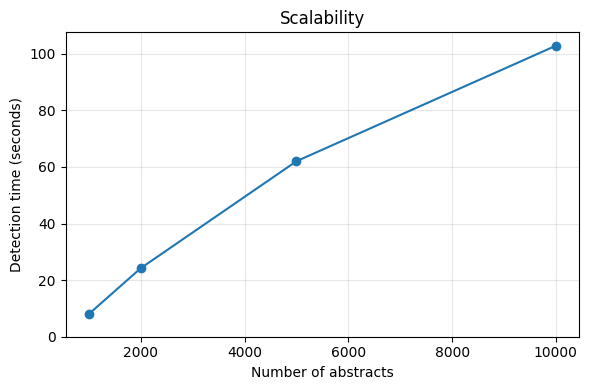

In [ ]:
if RUN_EXPERIMENTS:
    plt.figure(figsize=(6, 4))
    plt.plot(scale_table["papers"], scale_table["seconds"], "o-")
    plt.xlabel("Number of abstracts")
    plt.ylabel("Detection time (seconds)")
    plt.title("Scalability")
    plt.ylim(bottom=0)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "scalability.png", dpi=150)
    plt.show()


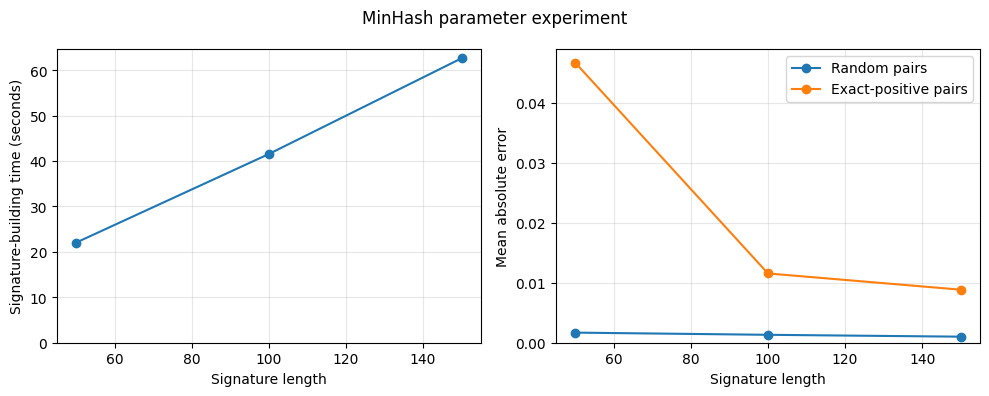

In [ ]:
if RUN_EXPERIMENTS:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(minhash_table["hashes"], minhash_table["seconds"], "o-")
    axes[0].set_ylabel("Signature-building time (seconds)")
    axes[1].plot(minhash_table["hashes"], minhash_table["random_pair_mae"], "o-", label="Random pairs")
    axes[1].plot(minhash_table["hashes"], minhash_table["positive_pair_mae"], "o-", label="Exact-positive pairs")
    axes[1].set_ylabel("Mean absolute error")
    axes[1].legend()
    for ax in axes:
        ax.set_xlabel("Signature length")
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.3)
    fig.suptitle("MinHash parameter experiment")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "minhash.png", dpi=150)
    plt.show()


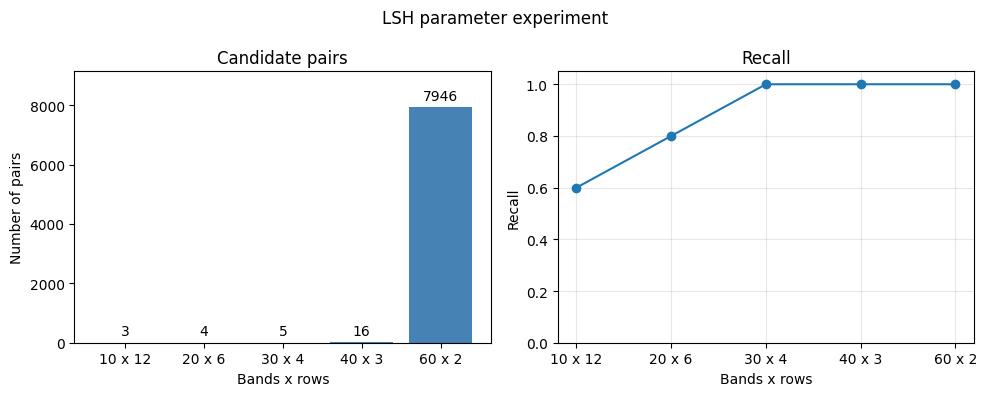

In [ ]:
if RUN_EXPERIMENTS:
    labels = [
        f"{b} x {r}"
        for b, r in zip(lsh_table["bands"], lsh_table["rows"])
    ]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    # Bar chart: number of candidate pairs
    bars = axes[0].bar(labels, lsh_table["candidates"], color="steelblue")
    axes[0].bar_label(bars, padding=3)
    axes[0].set_title("Candidate pairs")
    axes[0].set_xlabel("Bands x rows")
    axes[0].set_ylabel("Number of pairs")
    axes[0].set_ylim(0, lsh_table["candidates"].max() * 1.15)

    # Line chart: recall
    axes[1].plot(labels, lsh_table["recall"], marker="o")
    axes[1].set_title("Recall")
    axes[1].set_xlabel("Bands x rows")
    axes[1].set_ylabel("Recall")
    axes[1].set_ylim(0, 1.05)
    axes[1].grid(alpha=0.3)

    fig.suptitle("LSH parameter experiment")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "lsh.png", dpi=150)
    plt.show()